# Exploratory Data Analysis — BPI Challenge 2015, Municipality 1

This notebook explores the building-permit event log of one Dutch municipality (BPI Challenge 2015, Municipality 1).
The aim is to **understand the data** before any modelling decision is made.

**Scope of this notebook (EDA only):**

- The raw XES file is read only; it is never modified.
- No rows are dropped, filtered out of the data, imputed, or deduplicated. Subsets are used only as *views* for specific statistics, and each one is named and explained.
- No prediction target is defined, no predictive features are engineered, no train/test split is made, and no model is trained.
- Section 19 *discusses* candidate definitions of a "long-running case" but deliberately does not choose one.

**How to read it:** each section starts with a short explanation, then the code, then the output. Interpretation notes follow where useful.

# 1. Imports and settings

Only `pandas`, `numpy`, `matplotlib` and `pm4py` (for reading the XES file) are used.
Named constants are defined here so that no number in the analysis is unexplained.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pm4py

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

# Display and reporting constants
TOP_N_ACTIVITIES = 15          # requested size of the activity ranking
TOP_N_START_END = 10           # requested size of the start/end activity rankings
TOP_N_VARIANTS = 10            # requested size of the variant ranking
TOP_N_EXTREME = 10             # requested size of the extreme-case tables
TOP_N_RESOURCES = 10           # resources shown in the resource ranking
MIN_CATEGORY_SIZE = 20         # smallest group for which a median duration is shown (smaller medians are unstable)
DISAGREEMENT_DAYS = 30         # |A - B| above roughly one month is called an "extreme disagreement" between duration definitions
SECONDS_PER_DAY = 24 * 60 * 60
LOCAL_TIMEZONE = "Europe/Amsterdam"  # the municipality is Dutch; used only for calendar-year grouping
EXPECTED_EVENT_ROWS = 52_217   # validated in 01_data_loading.ipynb
EXPECTED_CASES = 1_199         # validated in 01_data_loading.ipynb



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




# 2. Dataset and output paths

Same robust approach as `01_data_loading.ipynb`: walk up from the current folder until the project root is found.
No absolute, user-specific path is used. Selected figures are written to `outputs/figures/`.

In [2]:
candidates = [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (folder for folder in candidates
     if (folder / "notebooks" / "01_data_loading.ipynb").is_file()
     and (folder / "src").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Start Jupyter from inside the capstone project.")
xes_path = project_root / "data" / "raw" / "BPIC15_1.xes"
if not xes_path.is_file():
    raise FileNotFoundError("Place BPIC15_1.xes in data/raw/ before running this notebook.")
figures_dir = project_root / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
print("Dataset:", xes_path.relative_to(project_root))
print("Figures:", figures_dir.relative_to(project_root))


def save_figure(filename):
    # Save the current matplotlib figure for possible presentation use.
    plt.savefig(figures_dir / filename, dpi=150, bbox_inches="tight")
    print("Saved:", (figures_dir / filename).relative_to(project_root))

Dataset: data\raw\BPIC15_1.xes
Figures: outputs\figures


# 3. Load the event log

The XES file is read with PM4Py and converted to a pandas DataFrame with one row per event.
The counts must match the intake validation (52,217 events, 1,199 cases); otherwise the notebook stops.

In [3]:
event_log = pm4py.read_xes(str(xes_path), return_legacy_log_object=True)
df = pm4py.convert_to_dataframe(event_log)

CASE = "case:concept:name"
ACTIVITY = "concept:name"
TIMESTAMP = "time:timestamp"
RESOURCE = "org:resource"

n_events, n_cases = len(df), df[CASE].nunique()
print(f"Event rows: {n_events:,}")
print(f"Cases:      {n_cases:,}")
if (n_events, n_cases) != (EXPECTED_EVENT_ROWS, EXPECTED_CASES):
    raise RuntimeError("STOP: counts differ from the validated intake counts.")

C:\SPAR_CAPSTONE\.venv\Lib\site-packages\pm4py\utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(


Event rows: 52,217
Cases:      1,199


**Event order.** Events are kept in the order of the XES file. The check below confirms that, within every case,
this order is already non-decreasing in time, so no re-sorting is needed (re-sorting could reorder events that share a timestamp).

In [4]:
in_time_order = df.groupby(CASE, sort=False)[TIMESTAMP].apply(lambda s: s.is_monotonic_increasing)
print("Cases whose events are in non-decreasing time order:", int(in_time_order.sum()), "of", n_cases)

same_time_as_previous = df[TIMESTAMP].eq(df.groupby(CASE, sort=False)[TIMESTAMP].shift())
print(f"Events sharing their timestamp with the previous event of the same case: {same_time_as_previous.mean():.1%}")
print("Timestamp hour (UTC) distribution, top 5:")
print(df[TIMESTAMP].dt.hour.value_counts().head(5).to_string())

Cases whose events are in non-decreasing time order: 1199 of 1199
Events sharing their timestamp with the previous event of the same case: 45.1%
Timestamp hour (UTC) distribution, top 5:
time:timestamp
22    13862
23    10128
9      4208
10     3946
8      3752


**Interpretation.** Most timestamps fall at 22:00 or 23:00 UTC, which is midnight in Dutch local time (winter/summer time).
Many events therefore carry a **date only, not a time of day**, and a large share of events tie with the previous event in the same case.
Consequences: durations are meaningful at day resolution, and the relative order of same-day events reflects the file order, not necessarily the true order.

# 4. Case-level table

One row per case, built in memory (nothing is saved). Structural columns are derived from the events;
case attributes (`case:*`) are copied from the events after checking that they are constant within each case.

In [5]:
case_attribute_columns = [col for col in df.columns if col.startswith("case:") and col != CASE]

# A case attribute should take a single value (including "missing") within a case.
values_per_case = df.groupby(CASE)[case_attribute_columns].nunique(dropna=False)
constancy = pd.DataFrame({
    "cases_with_more_than_one_value": (values_per_case > 1).sum(),
    "unique_values_overall": df[case_attribute_columns].nunique(),
    "dtype": df[case_attribute_columns].dtypes.astype(str),
})
display(constancy)
violations = constancy.query("cases_with_more_than_one_value > 0")
print("Case attributes that vary within a case:", list(violations.index) if len(violations) else "none")

,cases_with_more_than_one_value,unique_values_overall,dtype
case:endDate,0,478,"datetime64[us, UTC]"
case:caseStatus,0,3,str
case:SUMleges,0,613,float64
case:last_phase,0,27,str
case:case_type,0,1,str
case:Responsible_actor,0,20,str
case:parts,0,88,str
case:termName,0,13,str
case:endDatePlanned,0,86,"datetime64[us, UTC]"
case:startDate,0,741,"datetime64[us, UTC]"


Case attributes that vary within a case: none


In [6]:
grouped = df.groupby(CASE, sort=False)
cases = pd.DataFrame({
    "first_event_time": grouped[TIMESTAMP].min(),
    "last_event_time": grouped[TIMESTAMP].max(),
    "event_count": grouped.size(),
    "unique_activity_count": grouped[ACTIVITY].nunique(),
    "unique_resource_count": grouped[RESOURCE].nunique(),
})
cases["observed_duration_days"] = (
    (cases["last_event_time"] - cases["first_event_time"]).dt.total_seconds() / SECONDS_PER_DAY
)
# Attributes are constant per case (checked above), so the first event's value represents the case.
cases = cases.join(grouped[case_attribute_columns].first())
cases["case_level_duration_days"] = (
    (cases["case:endDate"] - cases["case:startDate"]).dt.total_seconds() / SECONDS_PER_DAY
)
cases.index.name = "case_id"
print("Case-level table shape:", cases.shape)
display(cases.head())

Case-level table shape: (1199, 22)


,first_event_time,last_event_time,event_count,unique_activity_count,unique_resource_count,observed_duration_days,case:endDate,case:caseStatus,case:SUMleges,case:last_phase,case:case_type,case:Responsible_actor,case:parts,case:termName,case:endDatePlanned,case:startDate,case:requestComplete,case:IDofConceptCase,case:landRegisterID,case:caseProcedure,case:Includes_subCases,case_level_duration_days
case_id,,,,,,,,,,,,,,,,,,,,,,
10009138,2014-04-10 22:00:00+00:00,2014-06-04 22:00:00+00:00,45,45,3,55.0,2014-07-17 22:00:00+00:00,O,157.09305,Beschikking verzonden,557669,560464,"Bouw,Reclame",Termijn bezwaar en beroep 1,2014-07-17 22:00:00+00:00,2014-04-10 22:00:00+00:00,TRUE,10009280,NaN,NaN,NaN,98.0
10051383,2014-04-16 22:00:00+00:00,2014-06-25 22:00:00+00:00,57,56,3,70.0,2014-08-07 22:00:00+00:00,O,1651.81640,Beschikking verzonden,557669,560464,Bouw,Termijn bezwaar en beroep 1,2014-08-07 22:00:00+00:00,2014-04-16 22:00:00+00:00,FALSE,10051546,NaN,NaN,NaN,113.0
10053042,2014-04-13 22:00:00+00:00,2014-07-02 22:00:00+00:00,57,56,3,80.0,2014-08-14 22:00:00+00:00,O,456.86386,Beschikking verzonden,557669,560912,Bouw,Termijn bezwaar en beroep 1,2014-08-14 22:00:00+00:00,2014-04-13 22:00:00+00:00,FALSE,10053184,NaN,NaN,NaN,123.0
10083315,2014-04-16 22:00:00+00:00,2014-07-16 22:00:00+00:00,58,57,3,91.0,NaT,O,339.47610,Beschikking verzonden,557669,560912,Bouw,Termijn bezwaar en beroep 1,NaT,2014-04-16 22:00:00+00:00,FALSE,10083477,NaN,NaN,NaN,NaN
10093171,2014-04-21 22:00:00+00:00,2014-07-09 22:00:00+00:00,46,46,3,79.0,2014-08-21 22:00:00+00:00,O,2868.74580,Beschikking verzonden,557669,560912,Bouw,Termijn bezwaar en beroep 1,2014-08-21 22:00:00+00:00,2014-04-21 22:00:00+00:00,TRUE,NaN,NaN,NaN,NaN,122.0


In [7]:
print("Values of the short categorical case attributes:")
for col in ["case:caseStatus", "case:requestComplete", "case:case_type", "case:Includes_subCases", "case:caseProcedure"]:
    print(f"\n{col}")
    print(cases[col].value_counts(dropna=False).to_string())

Values of the short categorical case attributes:

case:caseStatus
case:caseStatus
G    696
O    502
T      1

case:requestComplete
case:requestComplete
TRUE     948
FALSE    251

case:case_type
case:case_type
557669    1199

case:Includes_subCases
case:Includes_subCases
J      796
NaN    257
N      146

case:caseProcedure
case:caseProcedure
NaN           1093
Uitgebreid      88
Regulier        18


**Notes on case attributes (no meaning assumed beyond the data):**

- `case:case_type` has a **single value** for every case, so it cannot separate cases in this municipality.
- `case:caseStatus` has three codes (`G`, `O`, `T`). Their meaning is not documented in the log, so they are treated as labels only.
- `case:requestComplete` is stored as the text `TRUE`/`FALSE`.
- `case:parts` lists one or more permit components (e.g. `Bouw`, `Kap`), comma-separated.
- `case:SUMleges` is numeric (a fee total, judging by the name); it is not analysed further here.

# 5. Completeness / end-date analysis

How many cases have a recorded end date, and how does that relate to `case:requestComplete`?
These counts describe the data; they do **not** yet define the modelling cohort.

In [8]:
has_end_date = cases["case:endDate"].notna()
request_complete = cases["case:requestComplete"].str.upper().map({"TRUE": "true", "FALSE": "false"}).fillna("missing")

completeness = pd.Series({
    "cases with case:endDate": int(has_end_date.sum()),
    "cases without case:endDate": int((~has_end_date).sum()),
    "requestComplete = true": int((request_complete == "true").sum()),
    "requestComplete = false": int((request_complete == "false").sum()),
    "requestComplete missing": int((request_complete == "missing").sum()),
    "endDate present AND requestComplete = true": int((has_end_date & (request_complete == "true")).sum()),
}, name="cases")
display(completeness.to_frame())

print("Cross-tabulation (rows: caseStatus; columns: requestComplete / endDate present):")
display(pd.crosstab(cases["case:caseStatus"], [request_complete.rename("requestComplete"), has_end_date.rename("endDate present")], margins=True))

,cases
cases with case:endDate,956
cases without case:endDate,243
requestComplete = true,948
requestComplete = false,251
requestComplete missing,0
endDate present AND requestComplete = true,774


Cross-tabulation (rows: caseStatus; columns: requestComplete / endDate present):


requestComplete false       true        All
endDate present False True False True      
case:caseStatus                            
G                  17  101    87  491   696
O                  52   81    86  283   502
T                   0    0     1    0     1
All                69  182   174  774  1199

**Interpretation.** `endDate` presence and `requestComplete` are clearly *not* the same thing: some cases have an end date but
`requestComplete = FALSE`, and many cases have `requestComplete = TRUE` but no end date. Likewise `caseStatus` does not line up one-to-one with either field.
Which combination best represents "finished" is a decision for the target-definition step.

**Working view for Sections 6–7:** cases with a recorded `case:endDate` (the broadest set for which a completion date exists).
The stricter view "endDate present AND requestComplete = true" is reported alongside as a sensitivity check.

# 6. Duration analysis

Two duration definitions are compared:

- **A. Observed event-log duration** = last event timestamp − first event timestamp.
- **B. Case-level duration** = `case:endDate` − `case:startDate`.

Both are computed for cases with an end date (B is undefined otherwise). For cases *without* an end date, A only measures how long the case was observed, so it is not a completion duration.

In [9]:
completed = cases[has_end_date]
completed_strict = cases[has_end_date & (request_complete == "true")]

percentiles = [0.25, 0.50, 0.75, 0.90, 0.95]


def duration_summary(values):
    described = values.describe(percentiles=percentiles)
    return described.rename({"50%": "50% (median)"})


duration_stats = pd.DataFrame({
    "A: event log (endDate present)": duration_summary(completed["observed_duration_days"]),
    "B: startDate→endDate (endDate present)": duration_summary(completed["case_level_duration_days"]),
    "A: event log (strict view)": duration_summary(completed_strict["observed_duration_days"]),
    "B: startDate→endDate (strict view)": duration_summary(completed_strict["case_level_duration_days"]),
})
duration_stats = duration_stats.rename(index={"std": "standard deviation", "min": "minimum", "max": "maximum"})
print("Duration in days (strict view = endDate present AND requestComplete = true)")
display(duration_stats.round(1))

Duration in days (strict view = endDate present AND requestComplete = true)


,A: event log (endDate present),B: startDate→endDate (endDate present),A: event log (strict view),B: startDate→endDate (strict view)
count,956.0,956.0,774.0,774.0
mean,98.1,116.7,87.6,108.8
standard deviation,117.4,190.2,110.2,198.2
minimum,1.4,0.0,1.4,0.0
25%,47.4,45.0,43.0,40.0
50% (median),63.0,64.3,58.0,55.0
75%,102.5,98.2,93.4,93.0
90%,203.8,223.8,161.6,176.1
95%,307.4,358.0,259.1,330.4
maximum,1486.0,1540.5,1486.0,1540.5


### Comparing A and B

The difference A − B is positive when the event log extends beyond the recorded case dates.
Pearson correlation is sensitive to the extreme values; Spearman (rank) correlation shows whether the two definitions *order* cases similarly.

In [10]:
duration_a = completed["observed_duration_days"]
duration_b = completed["case_level_duration_days"]
difference = duration_a - duration_b

print(f"Pearson correlation A vs B:  {duration_a.corr(duration_b):.2f}")
print(f"Spearman correlation A vs B: {duration_a.corr(duration_b, method='spearman'):.2f}")
print("\nDifference A − B (days):")
print(difference.describe(percentiles=percentiles).round(1).to_string())

start_gap = (completed["first_event_time"] - completed["case:startDate"]).dt.total_seconds() / SECONDS_PER_DAY
end_gap = (completed["last_event_time"] - completed["case:endDate"]).dt.total_seconds() / SECONDS_PER_DAY
print(f"\nFirst event on the startDate day (|gap| < 1 day): {(start_gap.abs() < 1).mean():.1%} of completed cases")
print(f"Last event AFTER endDate:  {(end_gap > 0).mean():.1%}   median gap {end_gap.median():.1f} days")
print(f"Last event BEFORE endDate: {(end_gap < 0).mean():.1%}")
print(f"\nCases with |A − B| > {DISAGREEMENT_DAYS} days: {(difference.abs() > DISAGREEMENT_DAYS).sum()} of {len(completed)}")

Pearson correlation A vs B:  0.53


Spearman correlation A vs B: 0.80

Difference A − B (days):
count     956.0
mean      -18.6
std       162.5
min     -1502.2
25%         0.0
50%         6.0
75%         9.0
90%        17.5
95%        42.3
max       479.4

First event on the startDate day (|gap| < 1 day): 98.4% of completed cases
Last event AFTER endDate:  74.6%   median gap 6.0 days
Last event BEFORE endDate: 17.8%

Cases with |A − B| > 30 days: 194 of 956


In [11]:
disagreement = completed.assign(difference_days=difference).loc[
    lambda t: t["difference_days"].abs() > DISAGREEMENT_DAYS
]
print(f"Largest disagreements (top {TOP_N_EXTREME} by |A − B|):")
display(
    disagreement.reindex(disagreement["difference_days"].abs().sort_values(ascending=False).index)
    .head(TOP_N_EXTREME)[["case:startDate", "first_event_time", "case:endDate", "last_event_time",
                           "observed_duration_days", "case_level_duration_days", "difference_days",
                           "event_count", "case:last_phase"]]
    .round({"observed_duration_days": 1, "case_level_duration_days": 1, "difference_days": 1})
)

end_after_log = disagreement[disagreement["difference_days"] < -DISAGREEMENT_DAYS]
print(f"Cases whose endDate is more than {DISAGREEMENT_DAYS} days after the last event: {len(end_after_log)}")
print("Most frequent endDate days (local) among them:")
print(end_after_log["case:endDate"].dt.tz_convert(LOCAL_TIMEZONE).dt.date.value_counts().head(5).to_string())

Largest disagreements (top 10 by |A − B|):


,case:startDate,first_event_time,case:endDate,last_event_time,observed_duration_days,case_level_duration_days,difference_days,event_count,case:last_phase
case_id,,,,,,,,,
2876753,2010-11-22 23:00:00+00:00,2010-11-22 23:00:00+00:00,2015-01-06 15:13:24+00:00,2010-11-26 10:17:52+00:00,3.5,1505.7,-1502.2,6,Procedure afgebroken
2874224,2010-11-17 23:00:00+00:00,2010-11-17 23:00:00+00:00,2015-01-06 16:16:03+00:00,2011-01-12 23:00:00+00:00,56.0,1510.7,-1454.7,39,Aanvraag ontvangen
3020566,2011-01-11 23:00:00+00:00,2011-01-11 23:00:00+00:00,2015-01-06 15:18:18+00:00,2011-01-20 13:36:38+00:00,8.6,1455.7,-1447.1,6,Aanvraag ontvangen
2866083,2010-11-10 23:00:00+00:00,2010-11-10 23:00:00+00:00,2015-01-06 15:29:06+00:00,2011-01-24 23:00:00+00:00,75.0,1517.7,-1442.7,23,Aanvraag ontvankelijk
3019503,2011-01-05 23:00:00+00:00,2011-01-05 23:00:00+00:00,2015-01-06 15:29:40+00:00,2011-05-04 14:25:32+00:00,118.6,1461.7,-1343.0,27,Aanvraag ontvangen
2760925,2010-10-04 22:00:00+00:00,2010-10-04 22:00:00+00:00,2014-06-10 12:13:27+00:00,2010-10-07 12:57:14+00:00,2.6,1344.6,-1342.0,2,Buiten behandeling gelaten
2887729,2010-11-22 23:00:00+00:00,2010-11-22 23:00:00+00:00,2015-02-10 10:51:41+00:00,2011-12-27 23:00:00+00:00,400.0,1540.5,-1140.5,55,Vergunning verleend
2992191,2010-12-30 23:00:00+00:00,2010-12-30 23:00:00+00:00,2014-05-22 08:56:55+00:00,2011-04-21 13:27:53+00:00,111.6,1238.4,-1126.8,40,Procedure afgebroken
4088369,2011-11-07 23:00:00+00:00,2011-11-07 23:00:00+00:00,2014-12-23 10:50:00+00:00,2011-12-27 23:00:00+00:00,50.0,1141.5,-1091.5,35,Vergunning verleend


Cases whose endDate is more than 30 days after the last event: 132
Most frequent endDate days (local) among them:
case:endDate
2014-11-28    6
2015-01-28    6
2014-08-15    5
2015-01-06    5
2015-02-27    4


**Interpretation.**

- The first event almost always falls on the `startDate` day, so the two definitions agree on the **start**.
- They differ at the **end**: for most cases the last event comes a few days after `endDate` (typical gap about a week), which suggests some administrative steps are logged after the recorded end date. This makes A slightly longer than B for the typical case.
- A minority of cases disagree strongly in the other direction: `endDate` lies months or years after the last logged event. For those, B is much longer than A. Five of the six most extreme cases were started in 2010–2011 and share the same `endDate` day (6 January 2015, with a time-of-day stamp), which is consistent with a later administrative closing of old cases; across all such cases, however, end dates are spread out rather than concentrated on one day. Whether the event log is incomplete or `endDate` was set later cannot be determined from the data alone.
- The rank correlation is high while the linear correlation is moderate, i.e. the definitions mostly order cases the same way, but the extreme cases differ a lot.

No definition is chosen here. **The charts below use A** (fully derived from the events) for cases with an end date; the ECDF overlays B for comparison.

# 7. Duration visualisations

Each chart is its own figure. Units are days.

Saved: outputs\figures\duration_histogram.png


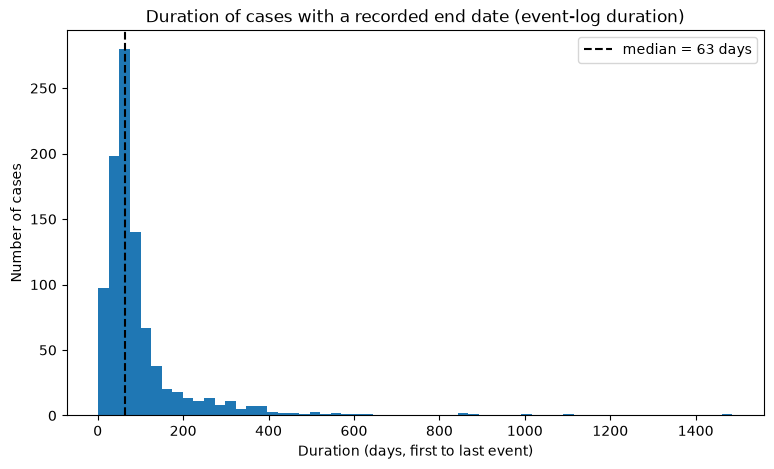

In [12]:
plt.figure(figsize=(9, 5))
plt.hist(duration_a, bins=60)
plt.axvline(duration_a.median(), linestyle="--", color="black", label=f"median = {duration_a.median():.0f} days")
plt.title("Duration of cases with a recorded end date (event-log duration)")
plt.xlabel("Duration (days, first to last event)")
plt.ylabel("Number of cases")
plt.legend()
save_figure("duration_histogram.png")
plt.show()

The distribution is strongly right-skewed: most cases finish within a few months, with a long tail of much longer cases.

Saved: outputs\figures\duration_boxplot.png


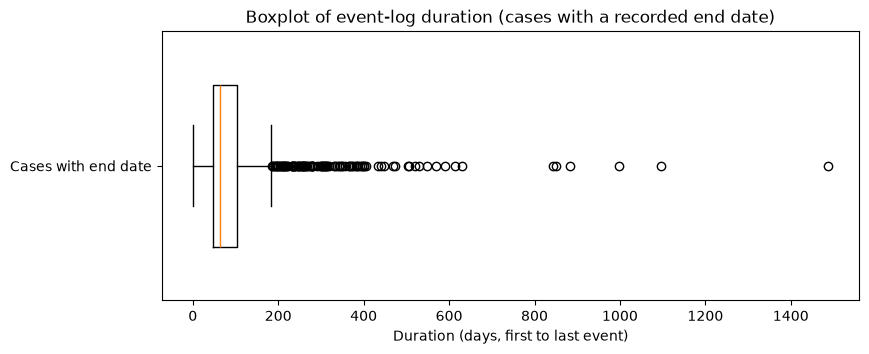

In [13]:
plt.figure(figsize=(9, 3.5))
plt.boxplot(duration_a, orientation="horizontal", widths=0.6)
plt.yticks([1], ["Cases with end date"])
plt.title("Boxplot of event-log duration (cases with a recorded end date)")
plt.xlabel("Duration (days, first to last event)")
save_figure("duration_boxplot.png")
plt.show()

The box covers the middle 50% of cases; points beyond the whiskers (1.5 × IQR) are drawn individually.
They are **shown, not removed** — Section 18 inspects them.

Saved: outputs\figures\duration_ecdf.png


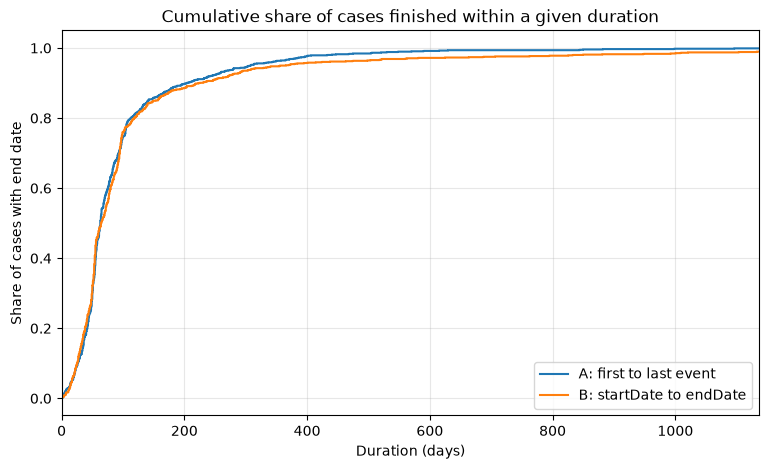

In [14]:
plt.figure(figsize=(9, 5))
for label, values in [("A: first to last event", duration_a), ("B: startDate to endDate", duration_b)]:
    ordered = np.sort(values.to_numpy())
    plt.step(ordered, np.arange(1, len(ordered) + 1) / len(ordered), where="post", label=label)
plt.title("Cumulative share of cases finished within a given duration")
plt.xlabel("Duration (days)")
plt.ylabel("Share of cases with end date")
plt.xlim(0, np.percentile(duration_b, 99))  # trim the far tail for readability; full range is in the table above
plt.grid(alpha=0.3)
plt.legend()
save_figure("duration_ecdf.png")
plt.show()

**Reading the ECDF:** for any duration on the x-axis, the y-value is the share of cases that took at most that long.
The x-axis is cut at the 99th percentile of B so the main body is readable; the statistics table above covers the full range.
The two curves are close over most of the range, consistent with the comparison in Section 6.

Saved: outputs\figures\duration_definitions_scatter.png


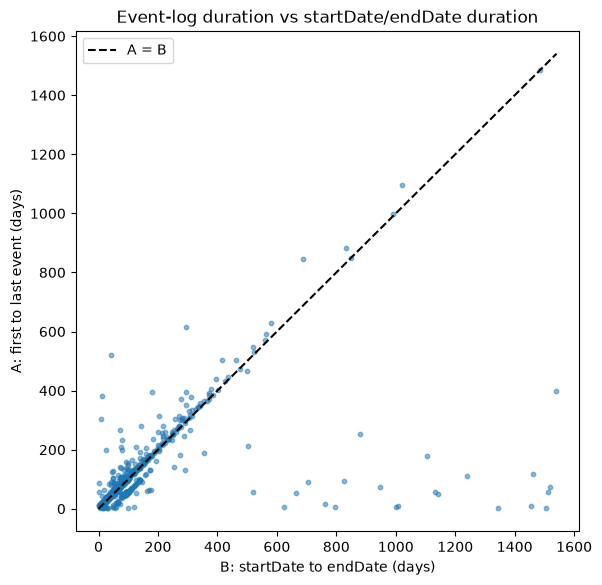

In [15]:
plt.figure(figsize=(6.5, 6.5))
plt.scatter(duration_b, duration_a, s=10, alpha=0.5)
upper = max(duration_a.max(), duration_b.max())
plt.plot([0, upper], [0, upper], linestyle="--", color="black", label="A = B")
plt.title("Event-log duration vs startDate/endDate duration")
plt.xlabel("B: startDate to endDate (days)")
plt.ylabel("A: first to last event (days)")
plt.legend()
save_figure("duration_definitions_scatter.png")
plt.show()

Points on the dashed line agree exactly. Points far **below** the line are cases whose `endDate` lies long after the last logged event.

# 8. Event count analysis (case complexity)

How many events, distinct activities, and distinct resources does a case involve? Computed for **all** 1,199 cases.

In [16]:
complexity = cases[["event_count", "unique_activity_count", "unique_resource_count"]]
display(complexity.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1))

,event_count,unique_activity_count,unique_resource_count
count,1199.0,1199.0,1199.0
mean,43.6,42.8,2.7
std,17.0,16.5,0.9
min,2.0,2.0,1.0
25%,37.0,37.0,2.0
50%,44.0,44.0,3.0
75%,53.0,52.0,3.0
90%,63.0,62.0,4.0
max,101.0,99.0,6.0


Saved: outputs\figures\event_count_histogram.png


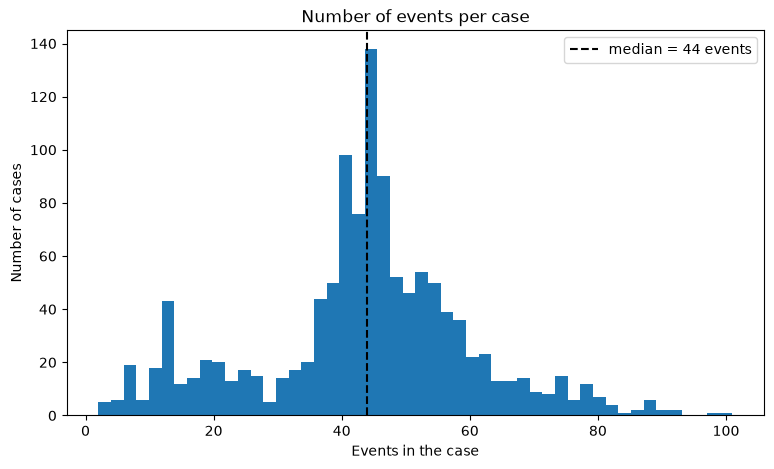

In [17]:
plt.figure(figsize=(9, 5))
plt.hist(cases["event_count"], bins=50)
plt.axvline(cases["event_count"].median(), linestyle="--", color="black",
            label=f"median = {cases['event_count'].median():.0f} events")
plt.title("Number of events per case")
plt.xlabel("Events in the case")
plt.ylabel("Number of cases")
plt.legend()
save_figure("event_count_histogram.png")
plt.show()

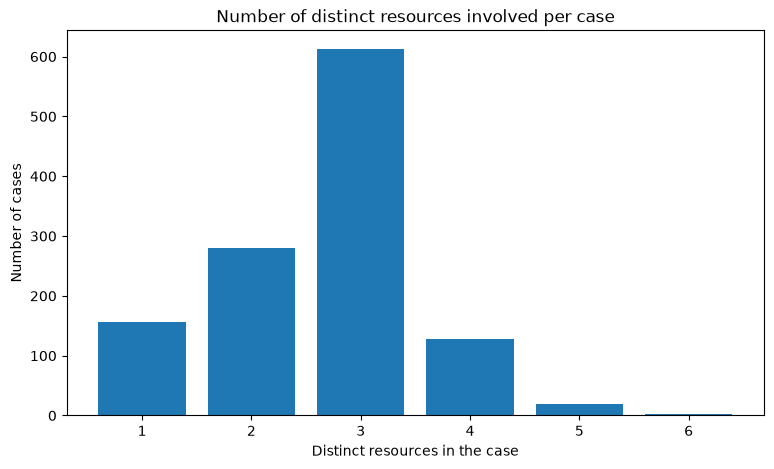

In [18]:
plt.figure(figsize=(9, 5))
resource_counts = cases["unique_resource_count"].value_counts().sort_index()
plt.bar(resource_counts.index, resource_counts.to_numpy())
plt.title("Number of distinct resources involved per case")
plt.xlabel("Distinct resources in the case")
plt.ylabel("Number of cases")
plt.show()

**Interpretation.** A typical case has a few dozen events but a long right tail; distinct activity counts track event counts closely
(most activities occur once per case — see Section 12). Most cases involve only a handful of resources.
A separate chart for `unique_activity_count` is not shown because it adds little beyond the event-count histogram and the table.

# 9. Most common activities

The log has three activity fields per event: `concept:name` / `action_code` (a code such as `01_HOOFD_010`) and
`activityNameEN` / `activityNameNL` (descriptions). Activities are counted **by code**, and labelled with their English name,
because one English name can belong to several codes (see the anomaly check below). Codes are not merged or cleaned.

In [19]:
# English label per code: the most frequent English name used with that code
code_to_english = df.groupby(ACTIVITY)["activityNameEN"].agg(lambda s: s.value_counts().index[0])

activity_counts = df[ACTIVITY].value_counts()
top_activities = pd.DataFrame({
    "activity_code": activity_counts.index[:TOP_N_ACTIVITIES],
    "english_name": code_to_english.reindex(activity_counts.index[:TOP_N_ACTIVITIES]).to_numpy(),
    "events": activity_counts.to_numpy()[:TOP_N_ACTIVITIES],
})
top_activities["percent_of_all_events"] = (top_activities["events"] / n_events * 100).round(2)
top_activities.index = range(1, len(top_activities) + 1)
print(f"Distinct activity codes: {df[ACTIVITY].nunique()}")
print(f"Top {TOP_N_ACTIVITIES} codes cover {top_activities['events'].sum() / n_events:.1%} of all events")
display(top_activities)

Distinct activity codes: 398
Top 15 codes cover 28.9% of all events


,activity_code,english_name,events,percent_of_all_events
1,01_HOOFD_010,register submission date request,1199,2.30
2,01_HOOFD_015,phase application received,1199,2.30
3,01_HOOFD_020,send confirmation receipt,1194,2.29
4,01_HOOFD_180,procedure change,1116,2.14
5,01_HOOFD_030_1,send confirmation receipt,1111,2.13
6,01_HOOFD_030_2,enter senddate acknowledgement,1053,2.02
7,01_HOOFD_200,send letter in progress,974,1.87
8,09_AH_I_010,article 34 WABO applies,933,1.79
9,01_HOOFD_375,phase advice known,933,1.79
10,01_HOOFD_380,grounds for refusal,930,1.78


Saved: outputs\figures\top_activities.png


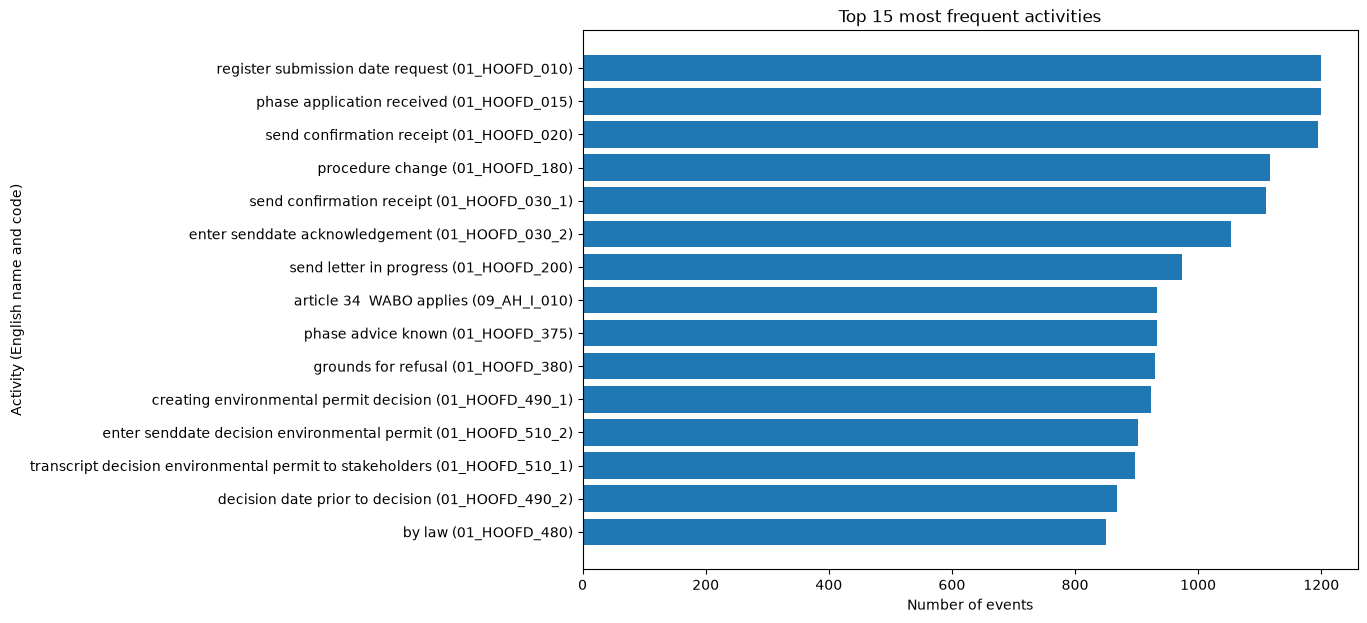

In [20]:
labels = top_activities["english_name"] + " (" + top_activities["activity_code"] + ")"
plt.figure(figsize=(10, 7))
plt.barh(labels[::-1], top_activities["events"][::-1])
plt.title(f"Top {TOP_N_ACTIVITIES} most frequent activities")
plt.xlabel("Number of events")
plt.ylabel("Activity (English name and code)")
save_figure("top_activities.png")
plt.show()

### Relationship between `action_code`, `concept:name` and `activityNameEN`

In [21]:
code_differs = df["concept:name"].ne(df["action_code"])
print("Events where concept:name differs from action_code:", int(code_differs.sum()))
display(df.loc[code_differs, ["concept:name", "action_code", "activityNameEN", TIMESTAMP]])

print("Distinct values -> concept:name:", df["concept:name"].nunique(),
      "| action_code:", df["action_code"].nunique(),
      "| activityNameEN:", df["activityNameEN"].nunique(),
      "| activityNameNL:", df["activityNameNL"].nunique())

codes_per_english = df.groupby("activityNameEN")[ACTIVITY].nunique()
english_per_code = df.groupby(ACTIVITY)["activityNameEN"].nunique()
print("English names used by more than one code:", int((codes_per_english > 1).sum()))
print("Codes used with more than one English name:", int((english_per_code > 1).sum()))

print("\nExamples: English names shared by the most codes")
display(codes_per_english.sort_values(ascending=False).head(5).rename("number_of_codes").to_frame())

example_code = english_per_code.sort_values(ascending=False).index[0]
print(f"Example: code {example_code} appears with these English names")
display(df.loc[df[ACTIVITY] == example_code, "activityNameEN"].value_counts().to_frame())

Events where concept:name differs from action_code: 1


,concept:name,action_code,activityNameEN,time:timestamp
26037,99_NOCODE_04,NaN,send letter receptive test not ok wait for report firedepartement,2013-03-14 09:36:35+00:00


Distinct values -> concept:name: 398 | action_code: 397 | activityNameEN: 289 | activityNameNL: 289
English names used by more than one code: 91
Codes used with more than one English name: 21

Examples: English names shared by the most codes


,number_of_codes
activityNameEN,
phase procedure aborted,7
start WABOprocedure,6
set decision status,6
enter senddate procedure confirmation,5
send confirmation receipt,4


Example: code 01_HOOFD_190_1 appears with these English names


,count
activityNameEN,
regular procedure applies,81
resume completeness subcases,53
send procedure confirmation,6


In [22]:
code_prefix = df[ACTIVITY].str.extract(r"^(\d+_[A-Z]+)", expand=False)
print("Events by code prefix (the part before the step number):")
print(code_prefix.value_counts(dropna=False).head(15).to_string())

Events by code prefix (the part before the step number):
concept:name
01_HOOFD    39724
08_AWB       3327
06_VD        1630
04_BPT       1251
11_AH        1045
09_AH         957
10_UOV        878
05_EIND       865
02_DRZ        832
01_BB         502
13_CRD        386
07_OPS        172
03_GBH        169
14_VRIJ       169
09_AWB        154


**Observations (not cleaned):**

- `concept:name` and `action_code` are identical except for **one event**, where `action_code` is missing and `concept:name` holds a placeholder code (`99_NOCODE_04`).
- There are more codes than English names: the **same English description is reused by several codes** (often the same step in different sub-processes, distinguished by the code prefix). A few codes also carry more than one English name.
- Counting by English name would therefore silently merge codes. Whether to merge them is a later decision.

# 10. Process starts and ends

The first and last event of each case in log order. Because many events share a date (Section 3),
the first/last activity among same-day events reflects the file order.

In [23]:
first_activity = grouped[ACTIVITY].first()
last_activity = grouped[ACTIVITY].last()


def ranked_activities(series, top_n):
    counts = series.value_counts().head(top_n)
    return pd.DataFrame({
        "activity_code": counts.index,
        "english_name": code_to_english.reindex(counts.index).to_numpy(),
        "cases": counts.to_numpy(),
        "percent_of_cases": (counts.to_numpy() / n_cases * 100).round(1),
    }, index=range(1, len(counts) + 1))


print(f"Distinct starting activities: {first_activity.nunique()}, distinct ending activities: {last_activity.nunique()}")
print(f"\nTop {TOP_N_START_END} starting activities")
display(ranked_activities(first_activity, TOP_N_START_END))
print(f"Top {TOP_N_START_END} ending activities (all cases, including those without an end date)")
display(ranked_activities(last_activity, TOP_N_START_END))

Distinct starting activities: 14, distinct ending activities: 108



Top 10 starting activities


,activity_code,english_name,cases,percent_of_cases
1,01_HOOFD_010,register submission date request,1138,94.9
2,01_HOOFD_011,OLO messaging active,34,2.8
3,11_AH_II_040b,set decision phase suspension decided,7,0.6
4,01_HOOFD_030_2,enter senddate acknowledgement,6,0.5
5,01_HOOFD_065_2,enter senddate procedure confirmation,4,0.3
6,02_DRZ_010,forward to the competent authority,2,0.2
7,01_HOOFD_065_0,create procedure confirmation,1,0.1
8,01_HOOFD_080,date for inspection MER,1,0.1
9,01_HOOFD_195_2,enter senddate procedure confirmation,1,0.1
10,05_EIND_020,enter date termination request received,1,0.1


Top 10 ending activities (all cases, including those without an end date)


,activity_code,english_name,cases,percent_of_cases
1,01_HOOFD_530,enter date publication decision environmental permit,295,24.6
2,01_HOOFD_510_2,enter senddate decision environmental permit,132,11.0
3,01_HOOFD_516,date decision for inspection,82,6.8
4,01_HOOFD_510_2a,start decision phase decision permitting sent,52,4.3
5,01_HOOFD_820,close case,51,4.3
6,01_BB_770,set phase: phase permitting irrevocable,33,2.8
7,01_HOOFD_030_2,enter senddate acknowledgement,30,2.5
8,01_HOOFD_519,create publication document,30,2.5
9,01_HOOFD_530a,set decision phase decision permitting published,29,2.4
10,01_HOOFD_520,generate publication document decision environmental permit,26,2.2


**Interpretation.** Starts are highly concentrated (registration of the request). Ends are much more spread out, which is expected:
cases finish via different routes, and cases still open at the end of the extract stop at an arbitrary step.

# 11. Process variants

A *variant* is the ordered sequence of activity codes of a case. Two cases share a variant only if their full sequences are identical.
Sequences are long, so an abbreviated form is shown (first steps … last steps).

In [24]:
VARIANT_HEAD, VARIANT_TAIL = 4, 2   # steps shown at the start / end of an abbreviated variant

variant_per_case = grouped[ACTIVITY].agg(tuple)
variant_counts = variant_per_case.value_counts()


def abbreviate(sequence):
    if len(sequence) <= VARIANT_HEAD + VARIANT_TAIL:
        return " → ".join(sequence)
    return " → ".join(sequence[:VARIANT_HEAD]) + f" → … ({len(sequence) - VARIANT_HEAD - VARIANT_TAIL} more) … → " + " → ".join(sequence[-VARIANT_TAIL:])


print(f"Unique variants: {len(variant_counts):,} for {n_cases:,} cases")
print(f"Variants that occur only once: {(variant_counts == 1).sum():,} ({(variant_counts == 1).mean():.1%} of variants)")
top_variants = pd.DataFrame({
    "cases": variant_counts.head(TOP_N_VARIANTS).to_numpy(),
    "percent_of_cases": (variant_counts.head(TOP_N_VARIANTS).to_numpy() / n_cases * 100).round(2),
    "length": [len(v) for v in variant_counts.head(TOP_N_VARIANTS).index],
    "abbreviated_variant": [abbreviate(v) for v in variant_counts.head(TOP_N_VARIANTS).index],
}, index=range(1, min(TOP_N_VARIANTS, len(variant_counts)) + 1))
with pd.option_context("display.max_colwidth", None):
    display(top_variants)
print(f"Median trace length over all cases: {variant_per_case.map(len).median():.0f} events")

Unique variants: 1,170 for 1,199 cases
Variants that occur only once: 1,155 (98.7% of variants)


,cases,percent_of_cases,length,abbreviated_variant
1,8,0.67,6,01_HOOFD_010 → 01_HOOFD_030_2 → 01_HOOFD_015 → 01_HOOFD_020 → 01_HOOFD_030_1 → 01_HOOFD_040
2,6,0.50,7,01_HOOFD_010 → 01_HOOFD_030_2 → 01_HOOFD_015 → 01_HOOFD_020 → … (1 more) … → 01_HOOFD_040 → 01_HOOFD_060
3,4,0.33,13,01_HOOFD_010 → 01_HOOFD_011 → 01_HOOFD_020 → 02_DRZ_010 → … (7 more) … → 01_HOOFD_030_1 → 01_HOOFD_030_2
4,3,0.25,5,01_HOOFD_010 → 01_HOOFD_030_2 → 01_HOOFD_015 → 01_HOOFD_020 → 01_HOOFD_030_1
5,3,0.25,12,01_HOOFD_010 → 01_HOOFD_011 → 05_EIND_010 → 01_HOOFD_015 → … (6 more) … → 01_HOOFD_065_1 → 01_HOOFD_101
6,2,0.17,3,01_HOOFD_010 → 01_HOOFD_011 → 01_HOOFD_015
7,2,0.17,13,01_HOOFD_010 → 01_HOOFD_011 → 01_HOOFD_020 → 02_DRZ_010 → … (7 more) … → 01_HOOFD_015 → 01_HOOFD_030_2
8,2,0.17,13,01_HOOFD_010 → 01_HOOFD_011 → 01_HOOFD_020 → 02_DRZ_010 → … (7 more) … → 01_HOOFD_061 → 01_HOOFD_030_2
9,2,0.17,13,01_HOOFD_010 → 01_HOOFD_011 → 01_HOOFD_020 → 02_DRZ_010 → … (7 more) … → 01_HOOFD_015 → 01_HOOFD_030_2
10,2,0.17,2,01_HOOFD_010 → 01_HOOFD_015


Median trace length over all cases: 44 events


**Interpretation.** Almost every case follows its own unique sequence. The few variants that repeat are **short** traces
(far below the median length), i.e. cases that stopped early; full-length cases are essentially all unique. This is typical for permit processes with many optional
steps and, here, amplified by same-day timestamp ties (the order of tied events is arbitrary). Exact variants are therefore
not a useful grouping on their own; coarser abstractions (e.g. which phases or activity sets occur) may be more informative later.

# 12. Rework / repeated activities (exploratory)

Definitions, per case:

- `repeated_event_count` = events that repeat an activity code already seen earlier in the same case (= `event_count − unique_activity_count`).
- `repeated_activity_count` = number of distinct activity codes that occur more than once in the case.
- `max_occurrences_of_one_activity` = how often the most-repeated code occurs.

These are descriptive only and are **not** used as features here.

In [25]:
occurrences = df.groupby([CASE, ACTIVITY], sort=False).size()
rework = pd.DataFrame({
    "repeated_event_count": cases["event_count"] - cases["unique_activity_count"],
    "repeated_activity_count": (occurrences > 1).groupby(level=CASE, sort=False).sum(),
    "max_occurrences_of_one_activity": occurrences.groupby(level=CASE, sort=False).max(),
})
display(rework.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1))
print(f"Cases with at least one repeated activity: {(rework['repeated_event_count'] > 0).sum()} of {n_cases}")

most_repeated = (occurrences[occurrences > 1].reset_index()[ACTIVITY].value_counts().head(TOP_N_RESOURCES))
print("\nActivity codes most often repeated within a case (number of cases where the code repeats):")
display(pd.DataFrame({"english_name": code_to_english.reindex(most_repeated.index), "cases_with_repeat": most_repeated}))

,repeated_event_count,repeated_activity_count,max_occurrences_of_one_activity
count,1199.0,1199.0,1199.0
mean,0.8,0.7,1.3
std,1.8,1.7,0.5
min,0.0,0.0,1.0
25%,0.0,0.0,1.0
50%,0.0,0.0,1.0
75%,1.0,1.0,2.0
90%,2.0,2.0,2.0
max,17.0,17.0,6.0


Cases with at least one repeated activity: 391 of 1199

Activity codes most often repeated within a case (number of cases where the code repeats):


,english_name,cases_with_repeat
concept:name,,
01_HOOFD_100,registrer date of publishing received request,187
08_AWB45_005,request complete,146
01_HOOFD_205,phase application receptive,89
01_HOOFD_180,procedure change,71
01_HOOFD_110,treat subcases completeness,70
01_HOOFD_120,subcases completeness completed,66
01_HOOFD_130,WAW permit aspect,50
01_HOOFD_200,send letter in progress,38
01_HOOFD_190_2,enter senddate procedure confirmation,19


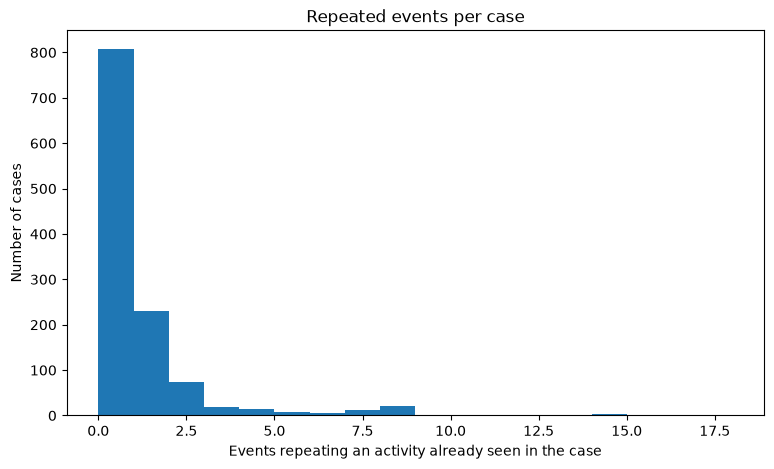

In [26]:
plt.figure(figsize=(9, 5))
plt.hist(rework["repeated_event_count"], bins=range(0, int(rework["repeated_event_count"].max()) + 2))
plt.title("Repeated events per case")
plt.xlabel("Events repeating an activity already seen in the case")
plt.ylabel("Number of cases")
plt.show()

**Interpretation.** Rework is not universal but common: a share of cases repeat at least one step, usually only a few times,
with a small number of cases repeating heavily. Whether repetition relates to duration is a question for the modelling stage.

# 13. Resource analysis

`org:resource` identifies who (or which system account) recorded an event. Resource identifiers are anonymised numbers.

> **Resource counts are used to understand process structure (hand-overs, concentration of work), not to assess employee performance.**

In [27]:
events_per_resource = df[RESOURCE].value_counts()
print(f"Unique resources overall: {events_per_resource.size}")
print("Events per resource:")
print(events_per_resource.describe().round(1).to_string())
top_resources = pd.DataFrame({
    "events": events_per_resource.head(TOP_N_RESOURCES),
    "percent_of_events": (events_per_resource.head(TOP_N_RESOURCES) / n_events * 100).round(1),
    "cases_involved": df.groupby(RESOURCE)[CASE].nunique().reindex(events_per_resource.head(TOP_N_RESOURCES).index),
})
top_resources["cumulative_percent"] = top_resources["percent_of_events"].cumsum().round(1)
print(f"\nTop {TOP_N_RESOURCES} resources by event count")
display(top_resources)
print("Resources per case:")
print(cases["unique_resource_count"].describe().round(1).to_string())

Unique resources overall: 23
Events per resource:
count       23.0
mean      2270.3
std       3704.7
min          9.0
25%         36.0
50%        461.0
75%       1614.5
max      12117.0

Top 10 resources by event count


,events,percent_of_events,cases_involved,cumulative_percent
org:resource,,,,
560872,12117,23.2,762,23.2
2670601,9886,18.9,427,42.1
3273854,9075,17.4,372,59.5
560890,7399,14.2,611,73.7
560912,5346,10.2,404,83.9
560925,1782,3.4,206,87.3
11744364,1447,2.8,72,90.1
560462,1443,2.8,59,92.9
560881,1076,2.1,61,95.0


Resources per case:
count    1199.0
mean        2.7
std         0.9
min         1.0
25%         2.0
50%         3.0
75%         3.0
max         6.0


**Interpretation.** Work is concentrated in a small number of resource identifiers; the top few account for most events.
The distinct-resources-per-case chart is in Section 8.

# 14. Temporal patterns

Calendar years are taken in Dutch local time (`Europe/Amsterdam`), because a timestamp of 23:00 UTC on 31 December is already
1 January locally.

> **Partial years:** the log starts in October 2010 and ends on 31 July 2015 (local time), so **2010 and 2015 are partial years**.
> Their counts are not comparable to full years. In addition, cases started near the end of the extract have had less time to finish,
> so recent years contain more open cases (right-censoring).

In [28]:
local_year = lambda series: series.dt.tz_convert(LOCAL_TIMEZONE).dt.year
print("Log time range (local):", df[TIMESTAMP].min().tz_convert(LOCAL_TIMEZONE).date(), "to",
      df[TIMESTAMP].max().tz_convert(LOCAL_TIMEZONE).date())

by_year = pd.DataFrame({
    "cases_started (startDate)": local_year(cases["case:startDate"]).value_counts(),
    "cases_started (first event)": local_year(cases["first_event_time"]).value_counts(),
    "cases_completed (endDate)": local_year(cases["case:endDate"].dropna()).value_counts(),
    "events": local_year(df[TIMESTAMP]).value_counts(),
}).sort_index().fillna(0).astype(int)
by_year.index.name = "year"
display(by_year)

started_per_year = local_year(cases["case:startDate"])
share_with_end = has_end_date.groupby(started_per_year).mean().mul(100).round(1)
print("Share of cases with an end date, by start year (%):")
print(share_with_end.to_string())

Log time range (local): 2010-10-05 to 2015-08-01


,cases_started (startDate),cases_started (first event),cases_completed (endDate),events
year,,,,
2010,78,79,10,1337
2011,353,353,266,13623
2012,302,304,255,12251
2013,202,200,197,11465
2014,235,235,183,11579
2015,29,28,45,1962


Share of cases with an end date, by start year (%):
case:startDate
2010    70.5
2011    84.4
2012    87.7
2013    91.6
2014    62.1
2015    24.1


Saved: outputs\figures\cases_by_year.png


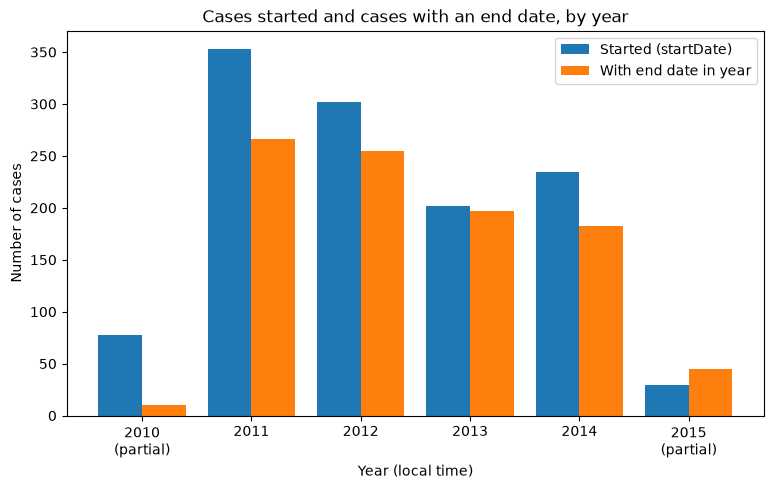

In [29]:
years = by_year.index.to_numpy()
bar_width = 0.4
plt.figure(figsize=(9, 5))
plt.bar(years - bar_width / 2, by_year["cases_started (startDate)"], width=bar_width, label="Started (startDate)")
plt.bar(years + bar_width / 2, by_year["cases_completed (endDate)"], width=bar_width, label="With end date in year")
plt.xticks(years, [f"{y}\n(partial)" if y in (years.min(), years.max()) else str(y) for y in years])
plt.title("Cases started and cases with an end date, by year")
plt.xlabel("Year (local time)")
plt.ylabel("Number of cases")
plt.legend()
save_figure("cases_by_year.png")
plt.show()

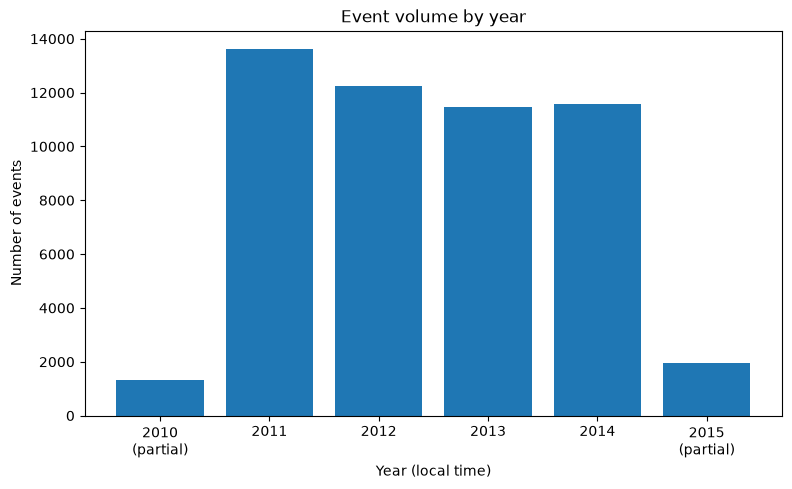

In [30]:
plt.figure(figsize=(9, 5))
plt.bar(years, by_year["events"])
plt.xticks(years, [f"{y}\n(partial)" if y in (years.min(), years.max()) else str(y) for y in years])
plt.title("Event volume by year")
plt.xlabel("Year (local time)")
plt.ylabel("Number of events")
plt.show()

**Interpretation.** Compare only full years (2011–2014) directly. The share of cases with an end date drops for the most recent start
years (2014, and especially 2015), consistent with censoring: those cases had less time to finish before the extract was taken.
The 2010 start cohort also has a lower share than 2011–2013. Data recording may have started in late 2010, but that cannot be confirmed from the log.

# 15. Case type / process category

`case:case_type`, `case:termName` and `case:last_phase` are inspected as recorded. Labels are Dutch; literal translations are
given only as reading aids and **do not imply any legal meaning**. Median durations are shown only for categories with at least
`MIN_CATEGORY_SIZE` cases with an end date.

In [31]:
def category_profile(column):
    profile = pd.DataFrame({
        "cases": cases[column].value_counts(dropna=False),
        "with_end_date": cases.loc[has_end_date, column].value_counts(dropna=False),
        "median_duration_A_days": completed.groupby(column, dropna=False)["observed_duration_days"].median().round(1),
        "median_duration_B_days": completed.groupby(column, dropna=False)["case_level_duration_days"].median().round(1),
    }).fillna({"with_end_date": 0}).astype({"with_end_date": int}).sort_values("cases", ascending=False)
    too_small = profile["with_end_date"] < MIN_CATEGORY_SIZE
    profile.loc[too_small, ["median_duration_A_days", "median_duration_B_days"]] = np.nan
    print(f"{column}: {cases[column].nunique()} distinct values, "
          f"{cases[column].isna().sum()} cases missing ({cases[column].isna().mean():.1%})")
    return profile


for column in ["case:case_type", "case:termName", "case:last_phase", "case:caseStatus"]:
    display(category_profile(column))

case:case_type: 1 distinct values, 0 cases missing (0.0%)


,cases,with_end_date,median_duration_A_days,median_duration_B_days
case:case_type,,,,
557669,1199,956,63.0,64.3


case:termName: 13 distinct values, 309 cases missing (25.8%)


,cases,with_end_date,median_duration_A_days,median_duration_B_days
case:termName,,,,
Termijn bezwaar en beroep 1,684,613,55.4,54.0
NaN,309,268,94.2,82.8
Termijn tot besluit,134,43,19.0,61.7
Termijn tot bezwaar buiten behandeling,18,13,NaN,NaN
Termijn aanvullende gegevens,14,5,NaN,NaN
Termijn ter inzage buiten behandeling,10,3,NaN,NaN
Termijn tot besluit verlengd,10,2,NaN,NaN
Termijn tot besluit omgezet,8,1,NaN,NaN
Termijn tot besluit na geen zienswijzen,4,1,NaN,NaN


case:last_phase: 27 distinct values, 0 cases missing (0.0%)


,cases,with_end_date,median_duration_A_days,median_duration_B_days
case:last_phase,,,,
Beschikking verzonden,400,336,55.0,67.0
Vergunning verleend,343,330,62.0,53.0
Zaak afgehandeld,108,106,95.1,83.8
Procedure afgebroken,88,51,61.4,68.0
Aanvraag ontvangen,72,17,NaN,NaN
Besluit onherroepelijk,45,36,176.2,113.2
Besluit genomen,37,33,64.4,83.0
Buiten behandeling gelaten,31,21,38.6,90.4
Advies bekend,20,8,NaN,NaN


case:caseStatus: 3 distinct values, 0 cases missing (0.0%)


,cases,with_end_date,median_duration_A_days,median_duration_B_days
case:caseStatus,,,,
G,696,592,64.0,59.3
O,502,364,62.0,77.0
T,1,0,NaN,NaN


**Literal reading aids** (not legal definitions): *Beschikking verzonden* ≈ "decision sent", *Vergunning verleend* ≈ "permit granted",
*Zaak afgehandeld* ≈ "case handled", *Procedure afgebroken* ≈ "procedure aborted", *Aanvraag ontvangen* ≈ "application received",
*Termijn bezwaar en beroep* ≈ "objection and appeal term", *Termijn tot besluit* ≈ "term until decision".

**Observations.**

- `case:case_type` is constant, so it gives **no** grouping in this municipality.
- `case:last_phase` has many values, a few dominant. Cases whose last phase is an early step (e.g. *Aanvraag ontvangen*) mostly lack an end date, so `last_phase` partly reflects *how far the case got*, i.e. it is an end-of-case state (see Section 20).
- `case:termName` is missing for about a quarter of cases; its values relate to legal time limits, so it may be informative but its timing must be checked before use.

# 16. Planned / due fields

Fields that look like deadlines or plan dates, inspected for coverage, type, examples and level (event vs case).
No lateness feature is constructed.

In [32]:
planned_fields = ["planned", "dueDate", "case:endDatePlanned", "dateFinished", "dateStop"]
rows = []
for column in planned_fields:
    is_case_level = column.startswith("case:")
    rows.append({
        "field": column,
        "level": "case" if is_case_level else "event",
        "dtype": str(df[column].dtype),
        "events_with_value": int(df[column].notna().sum()),
        "event_coverage_%": round(df[column].notna().mean() * 100, 1),
        "cases_with_any_value": int(df[column].notna().groupby(df[CASE]).any().sum()),
        "examples": ", ".join(str(v) for v in df[column].dropna().unique()[:2]),
    })
display(pd.DataFrame(rows).set_index("field"))

,level,dtype,events_with_value,event_coverage_%,cases_with_any_value,examples
field,,,,,,
planned,event,"datetime64[us, UTC]",46204,88.5,1199,"2014-04-15 07:30:39+00:00, 2014-04-15 07:34:03+00:00"
dueDate,event,"datetime64[us, UTC]",3340,6.4,1199,"2014-04-17 07:30:39+00:00, 2014-04-21 07:37:17+00:00"
case:endDatePlanned,case,"datetime64[us, UTC]",7127,13.6,137,"2014-07-17 22:00:00+00:00, 2014-08-07 22:00:00+00:00"
dateFinished,event,str,52217,100.0,1199,"2014-04-14 00:00:00, 2014-05-20 00:00:00"
dateStop,event,str,2,0.0,2,"2012-04-03 10:48:53, 2012-04-17 12:35:24"


In [33]:
date_finished = pd.to_datetime(df["dateFinished"], errors="coerce")  # in-memory parse for inspection only
print(f"dateFinished values parseable as datetimes: {date_finished.notna().mean():.1%}")
same_day = date_finished.dt.date.eq(df[TIMESTAMP].dt.tz_convert(LOCAL_TIMEZONE).dt.date)
print(f"dateFinished on the same local day as time:timestamp: {same_day.mean():.1%}")

planned_vs_event = (df["planned"] - df[TIMESTAMP]).dt.total_seconds() / SECONDS_PER_DAY
print("\nplanned − event timestamp (days), where planned exists:")
print(planned_vs_event.describe().round(1).to_string())

print("\ndueDate values per case:")
print(df["dueDate"].notna().groupby(df[CASE]).sum().describe().round(1).to_string())
print("\nActivities carrying a dueDate (top 5):")
print(df.loc[df["dueDate"].notna(), "activityNameEN"].value_counts().head(5).to_string())

planned_cases = cases[cases["case:endDatePlanned"].notna()]
print(f"\ncase:endDatePlanned present: {len(planned_cases)} cases; of these with endDate: {planned_cases['case:endDate'].notna().sum()}")
print("Rows where endDatePlanned equals endDate:",
      int((planned_cases["case:endDatePlanned"] == planned_cases["case:endDate"]).sum()))

dateFinished values parseable as datetimes: 100.0%


dateFinished on the same local day as time:timestamp: 85.3%



planned − event timestamp (days), where planned exists:
count    46204.0
mean        -1.2
std         23.3
min      -1012.6
25%          1.0
50%          1.0
75%          1.5
max       1097.4

dueDate values per case:


count    1199.0
mean        2.8
std         1.1
min         1.0
25%         2.0
50%         2.0
75%         3.0
max         5.0

Activities carrying a dueDate (top 5):
activityNameEN
register submission date request      1199
forward to the competent authority    1179
enter senddate acknowledgement         514
reception through OLO                  240
send confirmation receipt              207

case:endDatePlanned present: 137 cases; of these with endDate: 129
Rows where endDatePlanned equals endDate: 100


**Observations.**

- `planned` and `dueDate` are **event-level** datetimes. `planned` is present on most events and is typically about one day after the event's own timestamp; `dueDate` is on only a few events per case (but every case has at least one, mostly on the registration step).
- `case:endDatePlanned` is **case-level** and available for only a small minority of cases; for many of those it equals `endDate`, which raises the question of whether it was filled in at the end rather than planned in advance.
- `dateFinished` is stored as **text**, but parses as a datetime and is mostly on the same day as the event timestamp — it looks like a record-completion date.
- `dateStop` is almost entirely empty (two values).
- The *meaning* of these fields (when they are set, whether they are updated) is not documented in the log; this needs confirmation before any lateness feature is built.

# 17. Missingness

Missing values are counted, never filled. **Key** process columns are separated from optional/specialised attributes.
Case-level attributes are also counted per case (one row per case), which is the natural unit for them.

> High missingness does **not** automatically mean a column should be dropped: absence can itself be informative
> (e.g. a missing end date means "not finished in the extract"), or the field may only apply to certain case kinds.

In [34]:
key_columns = [CASE, ACTIVITY, TIMESTAMP, RESOURCE]
event_level_optional = ["action_code", "activityNameEN", "planned", "dueDate", "dateFinished", "dateStop", "question", "monitoringResource"]

def missing_table(frame, columns, group):
    return pd.DataFrame({
        "group": group,
        "missing": frame[columns].isna().sum(),
        "missing_%": (frame[columns].isna().mean() * 100).round(1),
    })

missingness = pd.concat([
    missing_table(df, key_columns, "KEY (event rows)"),
    missing_table(df, event_level_optional, "optional (event rows)"),
    missing_table(cases, case_attribute_columns, "case attribute (case rows)"),
])
display(missingness)

,group,missing,missing_%
case:concept:name,KEY (event rows),0,0.0
concept:name,KEY (event rows),0,0.0
time:timestamp,KEY (event rows),0,0.0
org:resource,KEY (event rows),0,0.0
action_code,optional (event rows),1,0.0
activityNameEN,optional (event rows),0,0.0
planned,optional (event rows),6013,11.5
dueDate,optional (event rows),48877,93.6
dateFinished,optional (event rows),0,0.0
dateStop,optional (event rows),52215,100.0


**Interpretation.** The key columns are complete. Missingness is concentrated in optional fields such as `dueDate`, `dateStop`,
`case:endDatePlanned`, `case:caseProcedure` and `case:landRegisterID`, which plausibly apply only to some cases or events.
The `question` column has no NaNs but uses the text `EMPTY` as a placeholder, so "no missing values" can hide empty content.

In [35]:
print("Most common values of 'question' (shows the EMPTY placeholder and mixed content):")
print(df["question"].value_counts().head(8).to_string())

Most common values of 'question' (shows the EMPTY placeholder and mixed content):
question
EMPTY                28546
False                15939
True                  5772
42                    1015
Uitgebreid              88
26 weken                18
Regulier                18
22-2-2012 0:00:00       18


# 18. Outliers / extreme cases

Structural fields only. Cases are **not** removed.

In [36]:
extreme_columns = ["observed_duration_days", "case_level_duration_days", "event_count", "unique_activity_count",
                   "unique_resource_count", "case:caseStatus", "case:requestComplete", "case:last_phase"]

print(f"{TOP_N_EXTREME} longest cases with an end date (by event-log duration A)")
display(completed.nlargest(TOP_N_EXTREME, "observed_duration_days")[extreme_columns].round(1))

print(f"{TOP_N_EXTREME} cases with the most events (all cases)")
display(cases.assign(has_end_date=has_end_date).nlargest(TOP_N_EXTREME, "event_count")[extreme_columns + ["has_end_date"]].round(1))

10 longest cases with an end date (by event-log duration A)


,observed_duration_days,case_level_duration_days,event_count,unique_activity_count,unique_resource_count,case:caseStatus,case:requestComplete,case:last_phase
case_id,,,,,,,,
2929114,1486.0,1485.8,93,76,3,G,TRUE,Besluit onherroepelijk
3564895,1096.0,1020.4,19,19,3,G,TRUE,Zaak afgehandeld
3690553,998.0,992.0,61,47,4,O,FALSE,Besluit onherroepelijk
3388781,882.0,833.0,83,80,2,G,TRUE,Besluit genomen
3327777,849.5,849.5,78,75,2,G,TRUE,Besluit genomen
5173437,844.0,687.0,78,78,3,G,TRUE,Zaak afgehandeld
3741124,629.6,581.0,80,77,3,G,FALSE,Beschikking verzonden
7079364,615.0,293.0,88,74,4,O,FALSE,Beschikking verzonden
7024496,590.0,563.0,101,99,2,G,FALSE,Zaak afgehandeld


10 cases with the most events (all cases)


,observed_duration_days,case_level_duration_days,event_count,unique_activity_count,unique_resource_count,case:caseStatus,case:requestComplete,case:last_phase,has_end_date
case_id,,,,,,,,,
7024496,590.0,563.0,101,99,2,G,FALSE,Zaak afgehandeld,True
4565008,919.0,NaN,98,86,3,O,FALSE,Besluit onherroepelijk,False
2929114,1486.0,1485.8,93,76,3,G,TRUE,Besluit onherroepelijk,True
7400998,330.0,303.0,93,92,2,G,FALSE,Zaak afgehandeld,True
9431949,280.5,217.0,91,90,3,O,FALSE,Besluit onherroepelijk,True
7948785,118.0,108.0,90,89,3,O,FALSE,Beschikking verzonden,True
7168922,357.0,340.0,89,88,2,G,FALSE,Zaak afgehandeld,True
7835964,215.5,215.0,89,88,5,G,FALSE,Besluit onherroepelijk,True
6224787,345.0,336.0,88,87,3,O,FALSE,Beschikking verzonden,True


**Discussion (neutral).**

- **Plausible long-running cases:** most of the longest cases also have high event counts and A ≈ B, with last phases such as *Besluit onherroepelijk* or *Zaak afgehandeld*. This is consistent with genuinely long procedures.
- **Possibly incomplete or open cases:** two of the ten highest-event cases have no end date (one with last phase *Bezwaar of beroep ontvangen*, ≈ "objection or appeal received"). They may still have been open when the data was extracted, so their final length is unknown.
- **Possible data anomalies:** a long case with relatively few events (e.g. over 1,000 days with 19 events), cases where A and B differ by hundreds of days, and the cases from Section 6 whose `endDate` lies years after the last event. These may reflect late administrative closure, pauses, or missing events. They are flags for review, not conclusions.
- Several long cases have `requestComplete = FALSE` despite having an end date, which again shows that the completion fields do not line up.

# 19. Candidate definitions for a "long-running case" — no final decision

The options below are compared to prepare the target-definition step. **None is chosen here.**
The sample sizes are computed live below.

In [37]:
p75_a = completed["observed_duration_days"].quantile(0.75)
p75_b = completed["case_level_duration_days"].quantile(0.75)
print(f"Cases with an end date: {len(completed)} (strict view with requestComplete = true: {len(completed_strict)})")
print(f"75th percentile of duration A: {p75_a:.1f} days -> about {(completed['observed_duration_days'] > p75_a).sum()} cases above")
print(f"75th percentile of duration B: {p75_b:.1f} days -> about {(completed['case_level_duration_days'] > p75_b).sum()} cases above")
print(f"Distinct case_type values: {cases['case:case_type'].nunique()}")
print(f"Cases with endDatePlanned: {cases['case:endDatePlanned'].notna().sum()}, "
      f"of which with endDate: {(cases['case:endDatePlanned'].notna() & has_end_date).sum()}")

Cases with an end date: 956 (strict view with requestComplete = true: 774)
75th percentile of duration A: 102.5 days -> about 239 cases above
75th percentile of duration B: 98.2 days -> about 239 cases above
Distinct case_type values: 1
Cases with endDatePlanned: 137, of which with endDate: 129


| Candidate | Advantages | Limitations | Sample size implications | Leakage risk |
|---|---|---|---|---|
| **A. Fixed percentile threshold** (e.g. duration above the 75th percentile of finished cases) | Simple, explainable, works for every finished case; class balance is controlled by construction (≈25% positive). | Threshold is relative to this log, not to a business norm; sensitive to which duration definition (A vs B) and which "finished" view is used; open cases are excluded, which biases towards shorter cases in recent years (censoring). | Uses all finished cases (hundreds), roughly a quarter positive. | The label uses the final duration; predictors must be restricted to information available at the prediction time. |
| **B. Threshold within `case_type`** (e.g. 75th percentile per type) | Would adjust for different "normal" durations across case kinds. | `case:case_type` has **one value** here, so this reduces to option A. A substitute grouping (e.g. `case:parts`, `case:caseProcedure`) would need justification and may itself be partly end-of-case information. | Per-group thresholds split the sample; small groups give unstable percentiles. | Grouping variable must be known at the start of the case. |
| **C. Planned end-date based** (finished after `case:endDatePlanned`) | Closest to an operational notion of "late". | `endDatePlanned` exists for only a small minority of cases and often equals `endDate`, which suggests it may be recorded at or after the end. Its meaning is not documented. | Very small sample; likely too few positives for a stable model. | High: if the planned date is set or revised late, it encodes the outcome. |

Event-level `planned` / `dueDate` fields (Section 16) might support a richer deadline-based definition later, but their semantics would need to be confirmed first.

# 20. Data leakage audit

Variables that describe how a case **ended** are not known while the case is running. They must not be used as predictors
when predicting, during the case, whether it will become long-running. This is a review list; no features are created.

In [38]:
leakage_audit = pd.DataFrame([
    ("case:endDate", "Completion date — only known at the end", "DO NOT USE AS PREDICTOR"),
    ("last event timestamp (last_event_time)", "Only known when the case is over", "DO NOT USE AS PREDICTOR"),
    ("final total duration (observed / case-level)", "This is the outcome itself", "DO NOT USE AS PREDICTOR"),
    ("final total event_count / unique activity / resource counts", "Known only after all events happened", "DO NOT USE AS PREDICTOR"),
    ("case:caseStatus (final)", "Snapshot status at extraction time", "DO NOT USE AS PREDICTOR"),
    ("case:last_phase", "Phase reached at the end / at extraction", "DO NOT USE AS PREDICTOR"),
    ("case:requestComplete", "Snapshot value; may only be set when complete", "DO NOT USE AS PREDICTOR"),
    ("last activity / full variant / total rework counts", "Require the full trace", "DO NOT USE AS PREDICTOR"),
    ("case:endDatePlanned", "Sparse; often equals endDate; timing unknown", "DO NOT USE AS PREDICTOR (until timing is verified)"),
    ("dateFinished, dateStop", "Recording/stop dates; may post-date the event", "DO NOT USE AS PREDICTOR (until timing is verified)"),
    ("case:termName, case:SUMleges, case:Includes_subCases, case:IDofConceptCase", "Case attributes as of extraction; may be updated during the case", "VERIFY TIMING BEFORE USE"),
], columns=["variable", "reason", "status"])
display(leakage_audit)

,variable,reason,status
0,case:endDate,Completion date — only known at the end,DO NOT USE AS PREDICTOR
1,last event timestamp (last_event_time),Only known when the case is over,DO NOT USE AS PREDICTOR
2,final total duration (observed / case-level),This is the outcome itself,DO NOT USE AS PREDICTOR
3,final total event_count / unique activity / resource counts,Known only after all events happened,DO NOT USE AS PREDICTOR
4,case:caseStatus (final),Snapshot status at extraction time,DO NOT USE AS PREDICTOR
5,case:last_phase,Phase reached at the end / at extraction,DO NOT USE AS PREDICTOR
6,case:requestComplete,Snapshot value; may only be set when complete,DO NOT USE AS PREDICTOR
7,last activity / full variant / total rework counts,Require the full trace,DO NOT USE AS PREDICTOR
8,case:endDatePlanned,Sparse; often equals endDate; timing unknown,DO NOT USE AS PREDICTOR (until timing is verified)
9,"dateFinished, dateStop",Recording/stop dates; may post-date the event,DO NOT USE AS PREDICTOR (until timing is verified)


**Candidate early-available variables that MAY be safe later** (each still needs a timing check):

- `case:startDate` and calendar information derived from it (month, weekday, year).
- `case:parts` (permit components requested) and `case:caseProcedure` (regular vs extended procedure), if they are fixed at application.
- `case:Responsible_actor`, if assigned at the start.
- The **prefix** of the event trace up to the prediction moment: activities, timestamps and resources of events that have already happened (e.g. events in the first *k* days), plus `planned`/`dueDate` values carried by those early events.
- Workload context at the start time (e.g. number of cases open in the log at that date), computed only from information before that date.

# 21. Presentation candidates

The charts below were judged most useful for a final presentation (interpretability, relevance to delay risk, visual clarity).
They are saved to `outputs/figures/`.

| # | Figure | File | Why |
|---|---|---|---|
| 1 | Duration histogram | `duration_histogram.png` | Shows the skewed distribution and the long tail that motivates the delay-risk question. |
| 2 | Duration ECDF (A vs B) | `duration_ecdf.png` | Answers "what share of cases finish within X days?" and shows the two duration definitions agree for most cases. |
| 3 | Duration boxplot | `duration_boxplot.png` | Compact summary with visible extreme cases. |
| 4 | Top activities | `top_activities.png` | Explains what the process consists of in plain English. |
| 5 | Cases by year | `cases_by_year.png` | Shows data coverage, partial years and the censoring issue. |
| 6 | Events per case | `event_count_histogram.png` | Shows variation in case complexity. |

`duration_definitions_scatter.png` is also saved as a backup slide for the A-vs-B duration discussion.

In [39]:
print("Figures currently in outputs/figures:")
for path in sorted(figures_dir.glob("*.png")):
    print(" -", path.name)

Figures currently in outputs/figures:
 - cases_by_year.png
 - duration_boxplot.png
 - duration_definitions_scatter.png
 - duration_ecdf.png
 - duration_histogram.png
 - event_count_histogram.png
 - top_activities.png


# 22. Summary

- Counts match the intake (52,217 events, 1,199 cases); all case attributes are constant within cases.
- Timestamps are effectively **date-level**; same-day ties are common, which limits fine-grained ordering and variant analysis.
- Completion is ambiguous: `endDate` presence, `requestComplete` and `caseStatus` do not coincide. The duration views in this notebook use cases with an end date, with a strict view as sensitivity check.
- Durations are strongly right-skewed. Event-log duration and `startDate`→`endDate` duration rank cases similarly but disagree strongly for a minority of cases.
- Nearly every case has a unique variant; rework is common but usually small.
- `case:case_type` is constant, so per-type thresholds are not possible as such; `endDatePlanned` is too sparse for a primary target.
- End-of-case attributes (`endDate`, `caseStatus`, `last_phase`, `requestComplete`, totals) are flagged as leakage risks.

**Not done here (by design):** no target definition, no feature engineering, no train/test split, no model, no processed dataset, no rows dropped, raw file untouched.